# Phase 1 - Dataset inspection and problem definition
**Project:** R2 Returns Fraud vs. Genuine Grievance Sorter

**Objective:** understand exactly what the data contains and exactly how we are scored *before* modelling.

**Deliverables (each has its own section below)**
1. Dataset schema report
2. Class-distribution chart
3. Missing-value and duplicate report
4. Evaluation-metric specification

> The hidden labels are training and evaluation targets. They are **never** inputs at inference time.

## 0. Setup
Put the organisers' CSVs in a `data/` folder next to this notebook (or one level up). `evaluate.py` is optional: if found, the notebook checks the cost matrix against it.

In [1]:
from pathlib import Path
import importlib.util

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_colwidth", 80)
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False})


def find_first(candidates, must_contain):
    for folder in candidates:
        if (Path(folder) / must_contain).exists():
            return Path(folder)
    raise FileNotFoundError(f"could not find {must_contain!r}; searched {[str(c) for c in candidates]}")


DATA_DIR = find_first(["data", "../data", "../FULL_CODE/data", "../../data"], "return_requests_train.csv")
print("data folder:", DATA_DIR.resolve())
SCORER = next(
    (
        p
        for p in [
            Path("evaluate.py"),
            Path("tools/evaluate.py"),
            Path("../tools/evaluate.py"),
            DATA_DIR.parent / "evaluate.py",
        ]
        if p.exists()
    ),
    None,
)
print(
    "official scorer:",
    SCORER.resolve() if SCORER else "not found (cost matrix will be checked against the README table only)",
)

data folder: /home/claude/r2_project/FULL_CODE/data
official scorer: /home/claude/r2_project/FULL_CODE/tools/evaluate.py


## 1. The problem in one page
A fashion retailer gets many returns. Most are honest; a small share are abusive (wardrobing, 'empty box' claims, serial returners). For every return request the system must output:

| output | meaning |
|---|---|
| `decision` | `auto_approve`, `inspect` (cheap human check) or `escalate` (serious action) |
| `confidence` | calibrated **P(abusive)** between 0 and 1 |
| `justification` | short, honest explanation of the decision |

A second task: name the **5 products with the most fit-related returns** (size-chart fixes).

Four hidden classes: `abusive`, `genuine_quality_issue`, `genuine_fit_issue`, `genuine_wrong_item`. The business decision only depends on how likely a return is abusive, but the genuine reason is useful for explanations and the size-chart task.

## 2. Load the files

In [2]:
FILES = {
    "train": "return_requests_train.csv",
    "test": "return_requests_test.csv",
    "products": "products.csv",
    "size_charts": "size_charts.csv",
    "customers": "customers.csv",
}
tables = {name: pd.read_csv(DATA_DIR / file) for name, file in FILES.items()}
train, test = tables["train"], tables["test"]
inventory = pd.DataFrame(
    {
        "file": list(FILES.values()),
        "rows": [len(t) for t in tables.values()],
        "columns": [t.shape[1] for t in tables.values()],
        "size_MB": [round((DATA_DIR / f).stat().st_size / 1e6, 2) for f in FILES.values()],
    },
    index=list(FILES),
)
inventory

,file,rows,columns,size_MB
train,return_requests_train.csv,43068,23,10.13
test,return_requests_test.csv,16932,22,3.68
products,products.csv,975,12,0.16
size_charts,size_charts.csv,1851,9,0.06
customers,customers.csv,20205,3,0.53


**Reading:** `train` + `test` together are the ~60,000 return requests. Only `train` has the `label` column; the test labels are hidden and used by the organisers' scorer.

## 3. Deliverable 1 - Dataset schema report

In [3]:
def schema(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "dtype": frame.dtypes.astype(str),
            "non_null": frame.notna().sum(),
            "missing_%": (frame.isna().mean() * 100).round(2),
            "unique": frame.nunique(),
            "example": frame.iloc[0],
        }
    )


schema(train)

,dtype,non_null,missing_%,unique,example
return_id,str,43068,0.00,43068,RET-07ZB0EH6
order_id,str,43068,0.00,38263,ORD-W96E2CBPN5
customer_id,str,43068,0.00,17196,CUS-2S8YNBVN
product_id,str,43068,0.00,975,PRD-SBHMRONV
category,str,43068,0.00,5,Footwear
sub_category,str,43068,0.00,24,formal shoes
size_ordered,str,43068,0.00,24,UK 8
order_date,str,43068,0.00,306,2025-09-24
delivery_date,str,43068,0.00,303,2025-09-27
return_request_date,str,43068,0.00,273,2025-10-01


In [4]:
for name in ["products", "size_charts", "customers"]:
    print(f"--- {name} {tables[name].shape}")
    display(schema(tables[name]))

--- products (975, 12)


,dtype,non_null,missing_%,unique,example
product_id,str,975,0.00,975,PRD-01317XS0
title,str,975,0.00,961,Gulmohar Threads Women's Yellow Linen Blend Solid with Border Saree
category,str,975,0.00,5,Women Ethnic
sub_category,str,975,0.00,24,saree
gender,str,975,0.00,2,women
brand,str,975,0.00,19,Gulmohar Threads
price_inr,int64,975,0.00,84,2099
available_sizes,str,975,0.00,13,Free Size
size_chart_id,str,885,9.23,321,NaN
fabric,str,975,0.00,34,linen blend


--- size_charts (1851, 9)


,dtype,non_null,missing_%,unique,example
size_chart_id,str,1851,0.00,321,SC-03RSNR
size,str,1851,0.00,23,XS
chest_cm,float64,1073,42.03,89,85.4
waist_cm,float64,1102,40.46,97,75.2
hip_cm,float64,1102,40.46,92,95.5
shoulder_cm,float64,1013,45.27,98,33.3
length_cm,float64,1211,34.58,233,62.5
inseam_cm,float64,226,87.79,21,NaN
foot_length_cm,float64,414,77.63,67,NaN


--- customers (20205, 3)


,dtype,non_null,missing_%,unique,example
customer_id,str,20205,0.0,20205,CUS-004HTRAT
signup_date,str,20205,0.0,2387,2024-11-21
city_tier,int64,20205,0.0,3,3


### Data dictionary - the role of every column in the main file

In [5]:
roles = {
    "return_id": "identifier (join key for the submission)",
    "order_id": "identifier (several returns can share an order)",
    "customer_id": "identifier -> customer history; links to customers.csv",
    "product_id": "identifier -> products.csv, size_charts.csv",
    "category": "feature (categorical)",
    "sub_category": "feature (categorical)",
    "size_ordered": "feature (categorical)",
    "order_date": "timestamp",
    "delivery_date": "timestamp",
    "return_request_date": "timestamp (defines time order)",
    "delivery_days": "feature (numeric)",
    "days_since_delivery": "feature (numeric) - late returns hint at wardrobing",
    "order_value_inr": "feature (numeric); also a fairness group (<1000 = low value)",
    "item_price_inr": "feature (numeric)",
    "discount_pct": "feature (numeric)",
    "items_in_order": "feature (numeric)",
    "payment_method": "feature (categorical)",
    "fulfilment_centre": "feature (categorical)",
    "customer_tenure_days": "feature (numeric); also a fairness group (<90 = new customer)",
    "prior_orders_count": "feature (numeric)",
    "prior_return_rate": "feature (numeric; empty when no prior orders)",
    "customer_reason": "free text, English / Hinglish / Hindi in Latin script, typos, emoji",
    "label": "TARGET - train only, never an input",
}
dictionary = pd.DataFrame({"role": pd.Series(roles)})
dictionary["in_train"] = dictionary.index.isin(train.columns)
dictionary["in_test"] = dictionary.index.isin(test.columns)
dictionary

,role,in_train,in_test
return_id,identifier (join key for the submission),True,True
order_id,identifier (several returns can share an order),True,True
customer_id,identifier -> customer history; links to customers.csv,True,True
product_id,"identifier -> products.csv, size_charts.csv",True,True
category,feature (categorical),True,True
sub_category,feature (categorical),True,True
size_ordered,feature (categorical),True,True
order_date,timestamp,True,True
delivery_date,timestamp,True,True
return_request_date,timestamp (defines time order),True,True


In [6]:
only_train = sorted(set(train.columns) - set(test.columns))
only_test = sorted(set(test.columns) - set(train.columns))
print("columns only in train:", only_train)
print("columns only in test :", only_test)
assert only_train == ["label"] and not only_test, "test must differ from train only by the label"

columns only in train: ['label']
columns only in test : []


### Which signals are available?

In [7]:
date_cols = ["order_date", "delivery_date", "return_request_date"]
for col in date_cols:
    train[col] = pd.to_datetime(train[col], errors="coerce")
    test[col] = pd.to_datetime(test[col], errors="coerce")
availability = pd.DataFrame(
    {
        "available?": ["yes", "yes", "yes", "yes (prior_return_rate, prior_orders_count)", "yes (customer_reason)"],
        "evidence": [
            f"return_request_date {train['return_request_date'].min().date()} .. {test['return_request_date'].max().date()}",
            f"{train['customer_id'].nunique():,} customers in train",
            f"{train['product_id'].nunique():,} products in train",
            "summary of earlier returns only; earlier decision outcomes exist only through train labels",
            f"{train['customer_reason'].notna().mean():.1%} non-empty",
        ],
    },
    index=["timestamps", "customer IDs", "product IDs", "previous-return information", "return reasons"],
)
availability

,available?,evidence
timestamps,yes,return_request_date 2025-10-01 .. 2026-09-30
customer IDs,yes,"17,196 customers in train"
product IDs,yes,975 products in train
previous-return information,"yes (prior_return_rate, prior_orders_count)",summary of earlier returns only; earlier decision outcomes exist only throug...
return reasons,yes (customer_reason),100.0% non-empty


In [8]:
periods = pd.DataFrame(
    {
        "first_request": [train["return_request_date"].min(), test["return_request_date"].min()],
        "last_request": [train["return_request_date"].max(), test["return_request_date"].max()],
        "rows": [len(train), len(test)],
    },
    index=["train", "test"],
)
print("test starts after train ends:", test["return_request_date"].min() > train["return_request_date"].max())
periods

test starts after train ends: True


,first_request,last_request,rows
train,2025-10-01,2026-06-30,43068
test,2026-07-01,2026-09-30,16932


**Reading:** the test period comes strictly *after* the training period, so the honest validation design is **time-based** (train on the past, check on the most recent months), never a random split.

## 4. Deliverable 2 - Class-distribution chart

,count,share
label,,
genuine_fit_issue,20721,0.4811
genuine_quality_issue,12059,0.2800
genuine_wrong_item,6927,0.1608
abusive,3361,0.0780


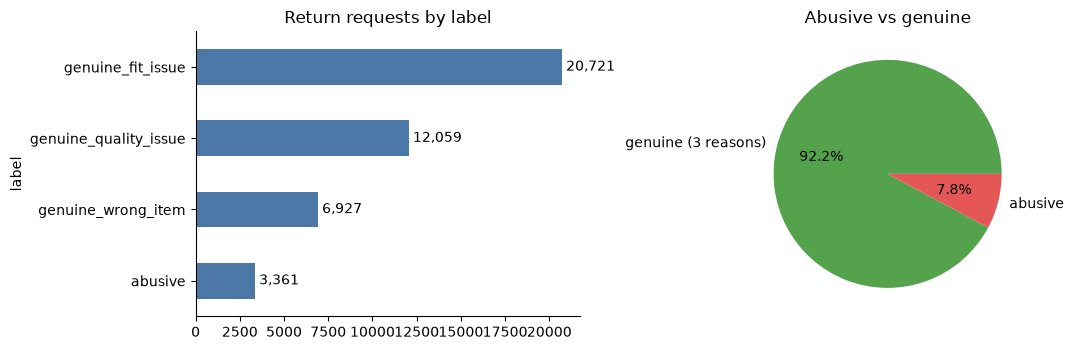

In [9]:
label_counts = train["label"].value_counts()
label_share = (label_counts / len(train)).round(4)
display(pd.DataFrame({"count": label_counts, "share": label_share}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
label_counts.sort_values().plot.barh(ax=axes[0], color="#4c78a8", title="Return requests by label")
for i, value in enumerate(label_counts.sort_values()):
    axes[0].text(value, i, f" {value:,}", va="center")
binary = (train["label"] == "abusive").map({True: "abusive", False: "genuine (3 reasons)"}).value_counts()
binary.plot.pie(ax=axes[1], autopct="%.1f%%", colors=["#54a24b", "#e45756"], ylabel="", title="Abusive vs genuine")
plt.tight_layout()
plt.show()

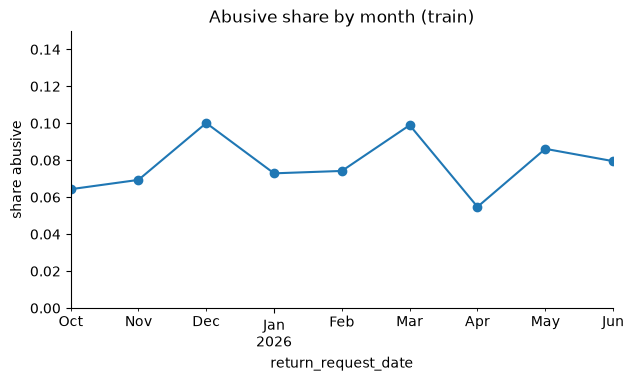

return_request_date
2025-10    0.064
2025-11    0.069
2025-12    0.100
2026-01    0.073
2026-02    0.074
2026-03    0.099
2026-04    0.055
2026-05    0.086
2026-06    0.079
Freq: M


In [10]:
monthly = train.groupby(train["return_request_date"].dt.to_period("M"))["label"].apply(
    lambda s: (s == "abusive").mean()
)
monthly.plot(marker="o", ylim=(0, 0.15), title="Abusive share by month (train)")
plt.ylabel("share abusive")
plt.show()
print(monthly.round(3).to_string())

**Reading:** about 8% of returns are abusive, so the data is imbalanced: *accuracy is a useless metric* (approving everything is 92% 'accurate'). The abusive share moves between about 5.5% and 10% from month to month (peaks in December and March), so the base rate is not fixed and calibration must be checked on recent months.

## 5. Deliverable 3 - Missing-value and duplicate report

### 5.1 Missing values

In [11]:
missing_all = pd.concat(
    {
        name: pd.DataFrame({"missing_count": t.isna().sum(), "missing_%": (t.isna().mean() * 100).round(2)})
        for name, t in tables.items()
    },
    names=["table", "column"],
)
print("Complete per-column report (every column of every table):")
with pd.option_context("display.max_rows", None):
    display(missing_all)
missing = missing_all[missing_all["missing_count"] > 0].reset_index()
print("Columns that actually contain missing values:")
missing

Complete per-column report (every column of every table):


missing_count  missing_%
table       column                                        
train       return_id                         0       0.00
            order_id                          0       0.00
            customer_id                       0       0.00
            product_id                        0       0.00
            category                          0       0.00
            sub_category                      0       0.00
            size_ordered                      0       0.00
            order_date                        0       0.00
            delivery_date                     0       0.00
            return_request_date               0       0.00
            delivery_days                     0       0.00
            days_since_delivery               0       0.00
            order_value_inr                   0       0.00
            item_price_inr                    0       0.00
            discount_pct                      0       0.00
            items_in_order                    0       0.00
            payment_method                    0       0.00
            fulfilment_centre                 0       0.00
            customer_tenure_days              0       0.00
            prior_orders_count                0       0.00
            prior_return_rate              3757       8.72
            customer_reason                   0       0.00
            label                             0       0.00
test        return_id                         0       0.00
            order_id                          0       0.00
            customer_id                       0       0.00
            product_id                        0       0.00
            category                          0       0.00
            sub_category                      0       0.00
            size_ordered                      0       0.00
            order_date                        0       0.00
            delivery_date                     0       0.00
            return_request_date               0       0.00
            delivery_days                     0       0.00
            days_since_delivery               0       0.00
            order_value_inr                   0       0.00
            item_price_inr                    0       0.00
            discount_pct                      0       0.00
            items_in_order                    0       0.00
            payment_method                    0       0.00
            fulfilment_centre                 0       0.00
            customer_tenure_days              0       0.00
            prior_orders_count                0       0.00
            prior_return_rate               918       5.42
            customer_reason                   0       0.00
products    product_id                        0       0.00
            title                             0       0.00
            category                          0       0.00
            sub_category                      0       0.00
            gender                            0       0.00
            brand                             0       0.00
            price_inr                         0       0.00
            available_sizes                   0       0.00
            size_chart_id                    90       9.23
            fabric                            0       0.00
            fit_type                          0       0.00
            colour                            0       0.00
size_charts size_chart_id                     0       0.00
            size                              0       0.00
            chest_cm                        778      42.03
            waist_cm                        749      40.46
            hip_cm                          749      40.46
            shoulder_cm                     838      45.27
            length_cm                       640      34.58
            inseam_cm                      1625      87.79
            foot_length_cm                 1437      77.63
customers   customer_i

Columns that actually contain missing values:


,table,column,missing_count,missing_%
0,train,prior_return_rate,3757,8.72
1,test,prior_return_rate,918,5.42
2,products,size_chart_id,90,9.23
3,size_charts,chest_cm,778,42.03
4,size_charts,waist_cm,749,40.46
5,size_charts,hip_cm,749,40.46
6,size_charts,shoulder_cm,838,45.27
7,size_charts,length_cm,640,34.58
8,size_charts,inseam_cm,1625,87.79
9,size_charts,foot_length_cm,1437,77.63


In [12]:
# Is the missing prior_return_rate explained by 'no prior orders'?
for name, frame in [("train", train), ("test", test)]:
    no_history = frame["prior_orders_count"] == 0
    print(
        f"{name}: prior_return_rate missing in {frame['prior_return_rate'].isna().sum():,} rows; "
        f"rows with prior_orders_count==0: {no_history.sum():,}; "
        f"missing exactly when no history: {(frame['prior_return_rate'].isna() == no_history).all()}"
    )

# Which size charts / sizes are empty, and why?
products = tables["products"]
print(
    "products without size_chart_id:",
    products["size_chart_id"].isna().sum(),
    "| their sizes:",
    products.loc[products["size_chart_id"].isna(), "available_sizes"].unique()[:5],
)

train: prior_return_rate missing in 3,757 rows; rows with prior_orders_count==0: 3,757; missing exactly when no history: True
test: prior_return_rate missing in 918 rows; rows with prior_orders_count==0: 918; missing exactly when no history: True
products without size_chart_id: 90 | their sizes: <ArrowStringArray>
['Free Size']
Length: 1, dtype: str


**Reading:** `prior_return_rate` is empty exactly for customers with no earlier orders, so the gap *is* a signal ('first order') and must be kept as missing, not filled with 0. Products without a size chart are free-size items. Any other missing values in the size-chart table are measurements that do not apply to a garment type.

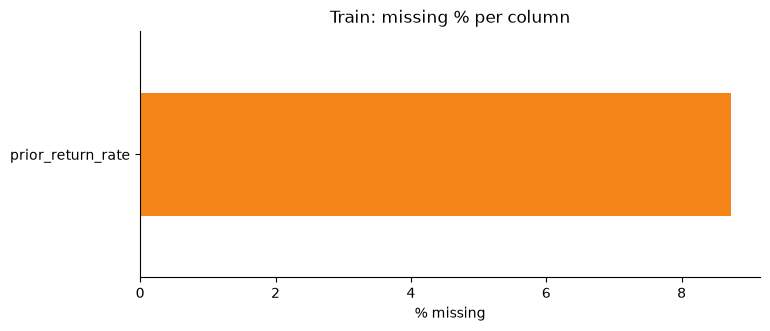

empty or blank customer_reason (train): 0


empty or blank customer_reason (test) : 0


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
(train.isna().mean() * 100).loc[lambda s: s > 0].plot.barh(ax=ax, color="#f58518", title="Train: missing % per column")
ax.set_xlabel("% missing")
plt.show()
print("empty or blank customer_reason (train):", int((train["customer_reason"].fillna("").str.strip() == "").sum()))
print("empty or blank customer_reason (test) :", int((test["customer_reason"].fillna("").str.strip() == "").sum()))

### 5.2 Duplicates and key integrity

In [14]:
def duplicate_report(frame: pd.DataFrame, name: str) -> dict:
    content_cols = [c for c in frame.columns if c not in {"return_id", "label"}]
    return {
        "table": name,
        "rows": len(frame),
        "duplicate full rows": int(frame.duplicated().sum()),
        "duplicate return_id": int(frame["return_id"].duplicated().sum()),
        "same content, different return_id": int(frame.duplicated(subset=content_cols).sum()),
        "orders with >1 return": int(frame["order_id"].duplicated().sum()),
        "same customer+product+size repeated": int(
            frame.duplicated(subset=["customer_id", "product_id", "size_ordered"]).sum()
        ),
    }


pd.DataFrame([duplicate_report(train, "train"), duplicate_report(test, "test")]).set_index("table").T

table,train,test
rows,43068,16932
duplicate full rows,0,0
duplicate return_id,0,0
"same content, different return_id",0,0
orders with >1 return,4805,1734
same customer+product+size repeated,105,20


### 5.2b Conflicting labels and repeated events

In [15]:
content = [c for c in train.columns if c not in {"return_id", "label"}]
same_content = train.groupby(content, dropna=False)["label"].nunique()
print(
    "groups of identical requests (all columns except id and label):",
    len(same_content),
    "| with conflicting labels:",
    int((same_content > 1).sum()),
)
by_event = train.groupby(["customer_id", "order_id", "product_id", "size_ordered"])["label"].agg(["size", "nunique"])
print(
    "customer+order+product+size events returned more than once:",
    int((by_event["size"] > 1).sum()),
    "| of those with different labels:",
    int(((by_event["size"] > 1) & (by_event["nunique"] > 1)).sum()),
)
print(
    "same return_id with different labels: 0 by construction (return_id is unique:", train["return_id"].is_unique, ")"
)

groups of identical requests (all columns except id and label): 43068 | with conflicting labels: 0
customer+order+product+size events returned more than once: 6 | of those with different labels: 3
same return_id with different labels: 0 by construction (return_id is unique: True )


**Reading:** there are no duplicate rows, no duplicate `return_id`s and no two identical requests with different labels. Only 6 customer+order+product+size events were returned twice, and 3 of those pairs carry different labels - that is a customer giving a different reason (or a different judged outcome) on the second return, not a data error. Repeated returns by the same customer are real behaviour and are kept as information.

In [16]:
ids_overlap = set(train["return_id"]) & set(test["return_id"])
print("return_ids shared between train and test:", len(ids_overlap))

customers, size_charts = tables["customers"], tables["size_charts"]
both = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)
integrity = pd.DataFrame(
    {
        "check": [
            "every product_id exists in products.csv",
            "every customer_id exists in customers.csv",
            "every size_chart_id of a product exists in size_charts.csv",
            "customer_id unique in customers.csv",
            "product_id unique in products.csv",
        ],
        "passes": [
            both["product_id"].isin(products["product_id"]).all(),
            both["customer_id"].isin(customers["customer_id"]).all(),
            products["size_chart_id"].dropna().isin(size_charts["size_chart_id"]).all(),
            customers["customer_id"].is_unique,
            products["product_id"].is_unique,
        ],
    }
)
integrity

return_ids shared between train and test: 0


,check,passes
0,every product_id exists in products.csv,True
1,every customer_id exists in customers.csv,True
2,every size_chart_id of a product exists in size_charts.csv,True
3,customer_id unique in customers.csv,True
4,product_id unique in products.csv,True


In [17]:
seen_in_train = test["customer_id"].isin(train["customer_id"])
print(f"test requests from customers already seen in train: {seen_in_train.mean():.1%}")
print(
    f"customers with more than one request overall: {both['customer_id'].duplicated(keep=False).groupby(both['customer_id']).first().mean():.1%}"
)

test requests from customers already seen in train: 73.7%
customers with more than one request overall: 71.2%


**Reading:** no duplicate `return_id`s, and joins to the catalogue are clean. Several returns can belong to the same order or customer - that is *real information* (repeat behaviour), not a data error, so we do not drop those rows. Because most test customers also appear in train, **customer-level leakage must be handled in Phase 2** (history features may only use the past; cross-validation must group by customer).

### 5.3 Sanity checks on values and dates

In [18]:
checks = {
    "order_date <= delivery_date": (train["order_date"] <= train["delivery_date"]).mean(),
    "delivery_date <= return_request_date": (train["delivery_date"] <= train["return_request_date"]).mean(),
    "days_since_delivery == return - delivery (days)": (
        (train["return_request_date"] - train["delivery_date"]).dt.days == train["days_since_delivery"]
    ).mean(),
    "delivery_days >= 0": (train["delivery_days"] >= 0).mean(),
    "order_value >= item_price": (train["order_value_inr"] >= train["item_price_inr"]).mean(),
    "0 <= discount_pct <= 100": train["discount_pct"].between(0, 100).mean(),
    "0 <= prior_return_rate <= 1 (where present)": train["prior_return_rate"].dropna().between(0, 1).mean(),
    "customer_tenure_days >= 0": (train["customer_tenure_days"] >= 0).mean(),
    "days_since_delivery <= 30 (return window)": (train["days_since_delivery"] <= 30).mean(),
}
pd.DataFrame({"share of rows passing": pd.Series(checks).round(4)})

,share of rows passing
order_date <= delivery_date,1.0
delivery_date <= return_request_date,1.0
days_since_delivery == return - delivery (days),1.0
delivery_days >= 0,1.0
order_value >= item_price,1.0
0 <= discount_pct <= 100,1.0
0 <= prior_return_rate <= 1 (where present),1.0
customer_tenure_days >= 0,1.0
days_since_delivery <= 30 (return window),1.0


In [19]:
train.select_dtypes("number").describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

,min,25%,50%,75%,max
delivery_days,1.0,2.0,4.00,5.00,9.0
days_since_delivery,0.0,1.0,4.00,14.00,30.0
order_value_inr,90.0,878.0,1600.00,2849.00,28197.0
item_price_inr,75.0,584.0,949.00,1574.00,13899.0
discount_pct,0.0,15.0,30.00,40.00,75.0
items_in_order,1.0,1.0,1.00,2.00,5.0
customer_tenure_days,1.0,189.0,448.00,831.00,2701.0
prior_orders_count,0.0,3.0,7.00,14.00,146.0
prior_return_rate,0.0,0.2,0.35,0.56,1.0


**Reading:** rows that fail a check are not deleted automatically - Phase 2 decides case by case. A return that is *late* (`days_since_delivery` near or over 30) is a feature, not an error.

## 6. Deliverable 4 - Evaluation-metric specification

### 6.1 The cost matrix (source of truth: the organisers' README and `evaluate.py`)
Rows are the true class, columns are our decision. **Lower total cost is better.**

In [20]:
ACTIONS = ["auto_approve", "inspect", "escalate"]
COST = pd.DataFrame(
    {"auto_approve": [0.0, 1.0], "inspect": [0.5, 0.3], "escalate": [10.0, 0.0]},
    index=["genuine (any of 3)", "abusive"],
)
COST

,auto_approve,inspect,escalate
genuine (any of 3),0.0,0.5,10.0
abusive,1.0,0.3,0.0


In [21]:
# Cross-check with the official scorer, if we can find it.
if SCORER is not None:
    spec = importlib.util.spec_from_file_location("official_evaluate", SCORER)
    official = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(official)
    for truth, row in official.COST.items():
        label = "abusive" if truth == "abusive" else "genuine (any of 3)"
        assert all(COST.loc[label, a] == row[a] for a in ACTIONS), f"mismatch for {truth}"
    print("cost matrix matches evaluate.py")
    print(
        "score weights   :",
        {"savings": official.W_SAVINGS, "fairness": official.W_FAIRNESS, "size_chart": official.W_SIZE_CHART},
    )
    print(
        "fairness cut-offs: low value <",
        official.LOW_VALUE_INR,
        "INR, new customer <",
        official.NEW_CUSTOMER_DAYS,
        "days",
    )
else:
    print("evaluate.py not found - using the README table above")

cost matrix matches evaluate.py
score weights   : {'savings': 0.7, 'fairness': 0.2, 'size_chart': 0.1}
fairness cut-offs: low value < 1000 INR, new customer < 90 days


### 6.1b The exact penalties, and the formulas that were floating around
Several different formulas have been written down during this project. **Only the last row is the benchmark.**

| source | wrongly escalate a genuine customer | miss an abuser (auto-approve) | inspect a genuine customer | inspect an abuser | verdict |
|---|---|---|---|---|---|
| pasted implementation plan: `10 x MissedFraud + 1 x WrongBlock + 0.2 x UnnecessaryInspect` | 1 | **10** | 0.2 | - | **reversed direction, rejected** |
| my earlier synthetic Phase 0 (`evaluate.py` of the synthetic project) | 1.7 | 1.0 | 0.2 | 0.5 | obsolete, replaced |
| review note: `10 x WrongBlock + 1 x MissedFraud + 0.2 x UnnecessaryInspect` | 10 | 1 | 0.2 | - | right direction, but the 0.2 is **not** the official value |
| **official `evaluate.py` / README** | **10** | **1** | **0.5** | **0.3** | **the benchmark** |

Definitions used in this project, taken from the official matrix:
- **wrong block** = `escalate` on a genuine return: cost 10
- **missed fraud** = `auto_approve` on an abusive return: cost 1
- **unnecessary inspect** = `inspect` on a genuine return: cost 0.5
- **inspect on an abuser** is not free either: cost 0.3 (cheaper than missing it, dearer than escalating it)
- **escalate an abuser** and **approve a genuine return**: cost 0

In [22]:
import inspect
import tempfile

if SCORER is None:
    print("evaluate.py not found - skipping the executable check")
else:
    source = inspect.getsource(official.score).splitlines()
    print("lines of official score() that compute the cost and the savings:")
    for line in source:
        if any(key in line for key in ("cost =", "cost_team", "cost_all_aa", "cost_oracle", "denom", "savings =")):
            print("   ", line.strip())
    # Run the real scorer on three trivial policies for the training rows.
    truth_cols = ["return_id", "label", "customer_tenure_days", "order_value_inr", "customer_reason"]
    abusive_flag = train["label"] == "abusive"
    policies = {
        "approve everything": pd.Series("auto_approve", index=train.index),
        "oracle (escalate abusers, approve the rest)": abusive_flag.map({True: "escalate", False: "auto_approve"}),
        "inspect everything": pd.Series("inspect", index=train.index),
    }
    rows = []
    with tempfile.TemporaryDirectory() as tmp:
        train[truth_cols].to_csv(Path(tmp) / "truth.csv", index=False)
        for name, decision in policies.items():
            pd.DataFrame(
                {"return_id": train["return_id"], "decision": decision, "confidence": 0.5, "justification": "x"}
            ).to_csv(Path(tmp) / "pred.csv", index=False)
            result = official.score(Path(tmp) / "pred.csv", Path(tmp) / "truth.csv", None, None)
            rows.append(
                {
                    "policy": name,
                    "total_cost": result["cost"]["team_total"],
                    "savings": result["components"]["savings"],
                    "primary_score": result["primary_score"],
                }
            )
    display(pd.DataFrame(rows).set_index("policy"))

lines of official score() that compute the cost and the savings:
    cost = np.array([COST[k][d] for k, d in zip(kind, df["decision"])])
    cost_team = float(cost.sum())
    cost_all_aa = float(sum(COST[k]["auto_approve"] for k in kind))
    cost_oracle = float(sum(min(COST[k].values()) for k in kind))
    denom = cost_all_aa - cost_oracle
    savings = (cost_all_aa - cost_team) / denom if denom > 0 else 0.0
    savings = float(min(1.0, max(-1.0, savings)))
    "cost": {"team_total": round(cost_team, 3), "team_mean_per_request": round(cost_team / len(df), 6),
    "all_auto_approve_total": round(cost_all_aa, 3), "oracle_total": round(cost_oracle, 3), "cost_matrix": COST},


,total_cost,savings,primary_score
policy,,,
approve everything,3361.0,0.0,0.0
"oracle (escalate abusers, approve the rest)",0.0,1.0,0.9
inspect everything,20861.8,-1.0,-0.7


**Reading:** the real scorer returns savings 0 for 'approve everything' and 1 for the oracle, and **clips** 'inspect everything' to -1 (its unclipped value is about -5.2). So the cost matrix, the savings formula and the score direction (higher primary score is better, lower cost is better) are all confirmed by running the official code, not just by reading it.

**Wrongly escalating one honest customer costs as much as missing ten abusers.** `inspect` is cheap but not free. This pushes the policy to be careful: escalate only when almost certain.

### 6.2 What that means for decisions
For a request with abuse probability *p*, the expected cost of each action is

- approve: `p * 1`
- inspect: `(1-p) * 0.5 + p * 0.3`
- escalate: `(1-p) * 10`

and the best action is the cheapest one. The break-even probabilities follow from the matrix:

approve -> inspect  when P(abusive) > 0.417
inspect -> escalate when P(abusive) > 0.969


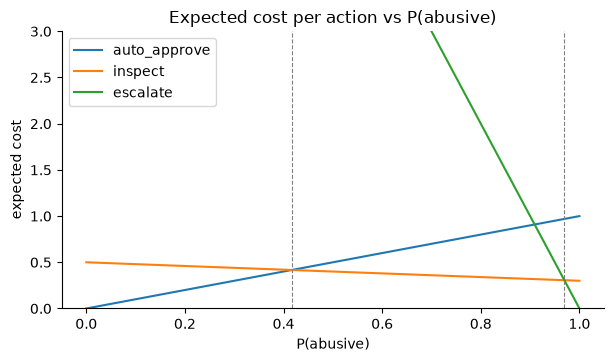

In [23]:
def expected_cost(p: np.ndarray) -> pd.DataFrame:
    p = np.asarray(p, dtype=float)
    return pd.DataFrame({a: (1 - p) * COST.loc["genuine (any of 3)", a] + p * COST.loc["abusive", a] for a in ACTIONS})


g, a = COST.loc["genuine (any of 3)"], COST.loc["abusive"]
approve_to_inspect = (g["auto_approve"] - g["inspect"]) / (
    (g["auto_approve"] - g["inspect"]) - (a["auto_approve"] - a["inspect"])
)
inspect_to_escalate = (g["inspect"] - g["escalate"]) / ((g["inspect"] - g["escalate"]) - (a["inspect"] - a["escalate"]))
print(f"approve -> inspect  when P(abusive) > {approve_to_inspect:.3f}")
print(f"inspect -> escalate when P(abusive) > {inspect_to_escalate:.3f}")

grid = np.linspace(0, 1, 201)
curves = expected_cost(grid)
curves.index = grid
ax = curves.plot(title="Expected cost per action vs P(abusive)")
for x in (approve_to_inspect, inspect_to_escalate):
    ax.axvline(x, color="grey", ls="--", lw=0.8)
ax.set_xlabel("P(abusive)")
ax.set_ylabel("expected cost")
ax.set_ylim(0, 3)
plt.show()

**Reading:** approve below ~0.42, inspect between ~0.42 and ~0.97, escalate only above ~0.97. This only works if the probabilities are **calibrated** - that is why calibration is its own phase.

### 6.3 Reference points: how much is there to win?

In [24]:
is_abusive = (train["label"] == "abusive").to_numpy()
cost_approve_all = np.where(is_abusive, a["auto_approve"], g["auto_approve"]).sum()
cost_oracle = np.where(is_abusive, a.min(), g.min()).sum()
cost_inspect_all = np.where(is_abusive, a["inspect"], g["inspect"]).sum()
cost_escalate_all = np.where(is_abusive, a["escalate"], g["escalate"]).sum()
reference = pd.DataFrame(
    {
        "total_cost": [cost_approve_all, cost_oracle, cost_inspect_all, cost_escalate_all],
        "savings_vs_approve_all": [
            (cost_approve_all - c) / (cost_approve_all - cost_oracle)
            for c in (cost_approve_all, cost_oracle, cost_inspect_all, cost_escalate_all)
        ],
    },
    index=["approve everything", "oracle (knows every label)", "inspect everything", "escalate everything"],
).round(3)
reference

,total_cost,savings_vs_approve_all
approve everything,3361.0,0.000
oracle (knows every label),0.0,1.000
inspect everything,20861.8,-5.207
escalate everything,397070.0,-117.140


**Reading:** *savings* = how much of the gap between 'approve everything' (0) and a perfect oracle (1) we close. Inspecting or escalating everything is **worse** than doing nothing (negative savings), so a model must be selective. The scorer clips savings to [-1, 1].

### 6.4 The full scoring formula
```
primary_score = 0.7 * savings + 0.2 * fairness_effective + 0.1 * size_chart_score
fairness_effective = fairness_score * min(1, max(0, savings) / 0.20)     # fairness only counts if savings > 0
```
| part | weight | definition |
|---|---|---|
| savings | 0.7 | (cost of approve-all - our cost) / (cost of approve-all - oracle cost), clipped to [-1, 1] |
| fairness | 0.2 | on **genuine** rows only: rate of being flagged (inspect or escalate), compared for *new (<90 days) vs established*, *low value (<1000 INR) vs other*, *non-English vs English*. Each pair: ratio of smoothed rates (+1 percentage point), score = clip(1 - (ratio - 1), 0, 1); fairness = mean of 3 pairs |
| size chart | 0.1 | overlap of our 5 product IDs with the true top 5 products by genuine fit-related returns |

Also reported (not in the primary score): calibration error and Brier score of `confidence` as P(abusive), and how many flagged requests had confidence below 0.2 - judges use this to catch 'fairness by inspecting extra low-risk customers'. Missing test IDs count as worst case; more than 50% missing is rejected.

### 6.5 Required submission format
| file | columns | rules |
|---|---|---|
| `submission/R2_predictions.csv` | `return_id, decision, confidence, justification` | every test `return_id` exactly once; decision in {auto_approve, inspect, escalate}; confidence a number in [0, 1] |
| `submission/R2_size_chart_top5.csv` | `rank, product_id` | exactly 5 rows, ranks 1-5, 5 distinct valid product IDs |

In [25]:
# A tiny executable specification of the submission rules (reused later as tests).
def validate_predictions(pred: pd.DataFrame, expected_ids: pd.Series) -> list[str]:
    problems = []
    required = ["return_id", "decision", "confidence", "justification"]
    if list(pred.columns[:4]) != required:
        problems.append(f"columns must start with {required}")
        return problems
    if pred["return_id"].duplicated().any():
        problems.append("duplicate return_id")
    if set(expected_ids) - set(pred["return_id"]):
        problems.append("some test return_ids are missing")
    if not pred["decision"].isin(ACTIONS).all():
        problems.append("invalid decision value")
    if not pd.to_numeric(pred["confidence"], errors="coerce").between(0, 1).all():
        problems.append("confidence outside [0, 1]")
    return problems


good = pd.DataFrame(
    {"return_id": test["return_id"], "decision": "auto_approve", "confidence": 0.08, "justification": "baseline"}
)
bad = good.iloc[:100].assign(decision="block")
print("valid example  ->", validate_predictions(good, test["return_id"]) or "no problems")
print("invalid example ->", validate_predictions(bad, test["return_id"]))

valid example  -> no problems
invalid example -> ['some test return_ids are missing', 'invalid decision value']


## 7. Are the date columns genuine event timestamps?
A time-based split is only defensible if the dates are real and internally consistent. We test that instead of assuming it.

split,train,test
unparseable dates,0.0,0.0
order <= delivery,1.0,1.0
delivery <= return request,1.0,1.0
days_since_delivery equals date difference,1.0,1.0
delivery_days equals date difference,1.0,1.0


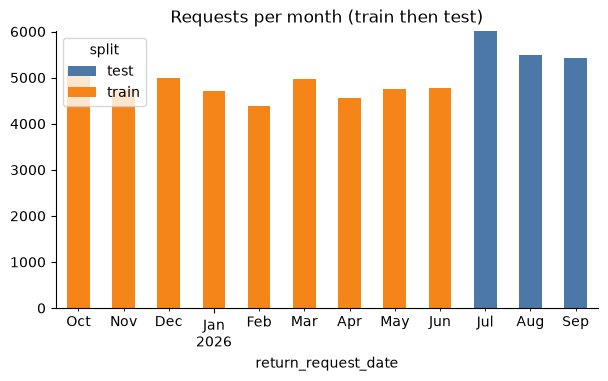

calendar days with no request at all: 0
last train day: 2026-06-30 | first test day: 2026-07-01


In [26]:
rows = []
for name, frame in [("train", train), ("test", test)]:
    rows.append(
        {
            "split": name,
            "unparseable dates": int(frame[date_cols].isna().sum().sum()),
            "order <= delivery": float((frame["order_date"] <= frame["delivery_date"]).mean()),
            "delivery <= return request": float((frame["delivery_date"] <= frame["return_request_date"]).mean()),
            "days_since_delivery equals date difference": float(
                ((frame["return_request_date"] - frame["delivery_date"]).dt.days == frame["days_since_delivery"]).mean()
            ),
            "delivery_days equals date difference": float(
                ((frame["delivery_date"] - frame["order_date"]).dt.days == frame["delivery_days"]).mean()
            ),
        }
    )
display(pd.DataFrame(rows).set_index("split").T)
both_dates = pd.concat([train.assign(split="train"), test.assign(split="test")])
per_month = (
    both_dates.groupby([both_dates["return_request_date"].dt.to_period("M"), "split"]).size().unstack(fill_value=0)
)
per_month.plot.bar(stacked=True, title="Requests per month (train then test)", color=["#4c78a8", "#f58518"])
plt.show()
days = pd.date_range(both_dates["return_request_date"].min(), both_dates["return_request_date"].max())
missing_days = days.difference(both_dates["return_request_date"].unique())
print("calendar days with no request at all:", len(missing_days))
print(
    "last train day:",
    train["return_request_date"].max().date(),
    "| first test day:",
    test["return_request_date"].min().date(),
)

**Reading:** the three dates agree with the numeric columns `delivery_days` and `days_since_delivery` on every row, so they are real event dates, not decoration. `return_request_date` is the clock for the time-based split. Train and test do not overlap in time (train ends 30 June 2026, test starts 1 July 2026).

## 8. Leakage audit of the catalogue and customer files
Fields that were computed from the labels (for example a per-product fit-issue proportion) would leak the target. We check names, and then scan every column for suspicious predictive power.

In [27]:
import re

suspicious = re.compile(r"prop|share|rate|return|fit_issue|label|abus|fraud|refund|complaint|score|risk", re.I)
for name in ["products", "size_charts", "customers"]:
    hits = [c for c in tables[name].columns if suspicious.search(c)]
    print(f"{name:12} columns: {list(tables[name].columns)}")
    print(f"{'':12} label-like names: {hits or 'none'}")
print()
print(
    "return_requests columns with label-like names:",
    [c for c in test.columns if suspicious.search(c) and c not in {"return_id", "return_request_date"}],
)

products     columns: ['product_id', 'title', 'category', 'sub_category', 'gender', 'brand', 'price_inr', 'available_sizes', 'size_chart_id', 'fabric', 'fit_type', 'colour']
             label-like names: none
size_charts  columns: ['size_chart_id', 'size', 'chest_cm', 'waist_cm', 'hip_cm', 'shoulder_cm', 'length_cm', 'inseam_cm', 'foot_length_cm']
             label-like names: none
customers    columns: ['customer_id', 'signup_date', 'city_tier']
             label-like names: none

return_requests columns with label-like names: ['prior_return_rate']


In [28]:
# Single-column leak scan: how well does ONE column (binned if numeric) reproduce the label on its own?
scan_source = train.merge(
    products[["product_id", "brand", "gender", "fabric", "fit_type", "colour", "price_inr"]],
    on="product_id",
    how="left",
)
scan_source = scan_source.merge(customers[["customer_id", "city_tier"]], on="customer_id", how="left")
ignore = {
    "return_id",
    "order_id",
    "customer_id",
    "product_id",
    "label",
    "abusive",
    "customer_reason",
    "order_date",
    "delivery_date",
    "return_request_date",
    "non_english",
    "n_words",
    "has_emoji",
}
majority = scan_source["label"].value_counts(normalize=True).iloc[0]
results = {}
for column in [c for c in scan_source.columns if c not in ignore]:
    values = scan_source[column]
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 20:
        values = pd.qcut(values, 20, duplicates="drop")
    table = pd.crosstab(values.astype(str), scan_source["label"])
    results[column] = table.max(axis=1).sum() / table.to_numpy().sum()
scan = pd.Series(results).sort_values(ascending=False).round(3).to_frame("label accuracy using only this column")
print(f"always guessing the majority label gives {majority:.3f}; a leaked label column would give close to 1.0")
scan

always guessing the majority label gives 0.481; a leaked label column would give close to 1.0


,label accuracy using only this column
size_ordered,0.521
sub_category,0.521
fit_type,0.521
fabric,0.498
days_since_delivery,0.495
price_inr,0.487
item_price_inr,0.484
brand,0.484
prior_return_rate,0.483
delivery_days,0.481


**Reading:** no catalogue or customer column carries label-derived content: the products and customers files hold only descriptive fields (title, brand, price, fabric, size chart, signup date, city tier), and no single column gets above 0.53 against a 0.48 majority baseline. The highest (size ordered, sub-category, fit type) have many levels and are legitimately linked to fit complaints, nowhere near the ~1.0 a leaked label column would give. Column names containing 'rate' or 'return' exist only in the request file (`prior_return_rate`, `return_request_date`) and describe the customer's *history up to the request*.

## 9. Train vs test: what drift is measured here?
We measure **covariate drift** (do the inputs look the same?). Label drift on the test period cannot be measured because its labels are hidden; the month-by-month label rate in section 4 is the only evidence we have.

In [29]:
def psi_numeric(a: pd.Series, b: pd.Series, bins: int = 10) -> float:
    edges = np.unique(np.quantile(a.dropna(), np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = pd.cut(a, edges).value_counts(normalize=True, sort=False) + 1e-4
    q = pd.cut(b, edges).value_counts(normalize=True, sort=False) + 1e-4
    return float(((p - q) * np.log(p / q)).sum())


def psi_categorical(a: pd.Series, b: pd.Series) -> float:
    p, q = a.value_counts(normalize=True), b.value_counts(normalize=True)
    index = p.index.union(q.index)
    p, q = p.reindex(index, fill_value=0) + 1e-4, q.reindex(index, fill_value=0) + 1e-4
    return float(((p - q) * np.log(p / q)).sum())


numeric_cols = [
    "delivery_days",
    "days_since_delivery",
    "order_value_inr",
    "item_price_inr",
    "discount_pct",
    "items_in_order",
    "customer_tenure_days",
    "prior_orders_count",
    "prior_return_rate",
]
category_cols = ["category", "sub_category", "size_ordered", "payment_method", "fulfilment_centre"]
drift = pd.DataFrame(
    {
        "type": ["numeric"] * len(numeric_cols) + ["categorical"] * len(category_cols),
        "train mean / top share": [train[c].mean() for c in numeric_cols]
        + [train[c].value_counts(normalize=True).iloc[0] for c in category_cols],
        "test mean / top share": [test[c].mean() for c in numeric_cols]
        + [test[c].value_counts(normalize=True).iloc[0] for c in category_cols],
        "PSI": [psi_numeric(train[c], test[c]) for c in numeric_cols]
        + [psi_categorical(train[c], test[c]) for c in category_cols],
    },
    index=numeric_cols + category_cols,
)
drift["verdict"] = np.where(drift["PSI"] < 0.1, "stable", np.where(drift["PSI"] < 0.25, "moderate", "large"))
display(drift.round(4))
print("rule of thumb: PSI < 0.1 stable, 0.1-0.25 moderate, > 0.25 large")

,type,train mean / top share,test mean / top share,PSI,verdict
delivery_days,numeric,3.7658,3.7280,0.0014,stable
days_since_delivery,numeric,8.0832,8.4052,0.0038,stable
order_value_inr,numeric,2188.3497,2059.3335,0.0076,stable
item_price_inr,numeric,1291.9649,1197.4963,0.0124,stable
discount_pct,numeric,27.7207,31.8651,0.0632,stable
items_in_order,numeric,1.7459,1.7505,0.0000,stable
customer_tenure_days,numeric,590.8833,655.0609,0.0296,stable
prior_orders_count,numeric,11.0846,12.8772,0.0302,stable
prior_return_rate,numeric,0.3908,0.4071,0.0191,stable
category,categorical,0.3987,0.3987,0.0004,stable


rule of thumb: PSI < 0.1 stable, 0.1-0.25 moderate, > 0.25 large


In [30]:
# Do reason texts repeat across the split boundary? (template leakage)
def normalised(texts: pd.Series) -> pd.Series:
    return texts.fillna("").str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" ")


train_texts, test_texts = normalised(train["customer_reason"]), normalised(test["customer_reason"])
print(f"test reason texts that appear verbatim in train: {test_texts.isin(set(train_texts)).mean():.1%}")
cutoff = pd.Timestamp("2026-05-01")
early, late_part = (
    train_texts[train["return_request_date"] < cutoff],
    train_texts[train["return_request_date"] >= cutoff],
)
print(f"train May-June texts that appear verbatim before May: {late_part.isin(set(early)).mean():.1%}")
duplicates = train_texts.duplicated(keep=False)
print(f"train rows whose exact text occurs more than once: {duplicates.mean():.1%}")
print(
    "abuse rate of rows with a very common text (>=50 uses):",
    round(float((train["label"] == "abusive")[train_texts.map(train_texts.value_counts()) >= 50].mean()), 3),
    "| rows:",
    int((train_texts.map(train_texts.value_counts()) >= 50).sum()),
)

test reason texts that appear verbatim in train: 27.4%
train May-June texts that appear verbatim before May: 26.6%
train rows whose exact text occurs more than once: 28.2%
abuse rate of rows with a very common text (>=50 uses): 0.074 | rows: 2454


**Reading:** every input is stable between train and test (all PSI below 0.1; the largest is discount at 0.063, which matches the 28 -> 32 average discount shift). About 27% of test reason texts also appear word for word in train, and 28% of train rows share their exact text with another row. A text model may recognise *phrases*, which is fine, but it must be cross-validated **grouped by customer and by time** so that a customer's own earlier wording cannot leak into their later rows. That rule is carried into Phase 2.

## References supplied for this project
Only the first group below has been used directly so far (calibration, explanations, fairness). The others were provided by the project owner and will be reviewed when their phase starts.

- Guo et al., *On Calibration of Modern Neural Networks* - https://arxiv.org/abs/1706.04599 (calibration, Phase 8)
- Lundberg & Lee, *A Unified Approach to Interpreting Model Predictions (SHAP)* - https://arxiv.org/abs/1705.07874 (explanations, Phase 12)
- Kearns et al., *Preventing Fairness Gerrymandering* - https://proceedings.mlr.press/v80/kearns18a.html (subgroup fairness, Phase 10)
- https://arxiv.org/pdf/2607.27143.pdf (supplied; not yet reviewed)
- https://www.tandfonline.com/doi/full/10.1080/2573234X.2020.1776164 (supplied; not yet reviewed)
- https://www.vldb.org/pvldb/vol19/p670-jackson.pdf (supplied; not yet reviewed)
- https://icml.cc/virtual/2025/47490 (supplied; not yet reviewed)

## 10. Data-leakage guard rails agreed for the rest of the project

1. `label` is never a model input; label-derived history is allowed **only** from requests that happened earlier and whose outcome could already be known.
2. Features for a request use only information dated **before** that request.
3. Validation is time-based (train on the past, test on the latest months); cross-validation groups by customer.
4. Language of the text is **not** a model feature (it is a fairness group, and could become a proxy).
5. Preprocessing (encoders, TF-IDF) is fitted on training rows only.

## 11. Phase 1 summary

In [31]:
summary = pd.Series(
    {
        "return requests (train + test)": f"{len(train) + len(test):,}",
        "train period": f"{train['return_request_date'].min().date()} to {train['return_request_date'].max().date()}",
        "test period": f"{test['return_request_date'].min().date()} to {test['return_request_date'].max().date()}",
        "abusive share (train)": f"{(train['label'] == 'abusive').mean():.1%}",
        "columns missing values": ", ".join(sorted(set(missing["column"]))) or "none",
        "duplicate return_id": int(train["return_id"].duplicated().sum() + test["return_id"].duplicated().sum()),
        "test customers seen in train": f"{seen_in_train.mean():.1%}",
        "approve -> inspect threshold": round(approve_to_inspect, 3),
        "inspect -> escalate threshold": round(inspect_to_escalate, 3),
    }
)
summary.to_frame("Phase 1 findings")

,Phase 1 findings
return requests (train + test),"60,000"
train period,2025-10-01 to 2026-06-30
test period,2026-07-01 to 2026-09-30
abusive share (train),7.8%
columns missing values,"chest_cm, foot_length_cm, hip_cm, inseam_cm, length_cm, prior_return_rate, s..."
duplicate return_id,0
test customers seen in train,73.7%
approve -> inspect threshold,0.417
inspect -> escalate threshold,0.969


**Findings carried into Phase 2**
- Imbalanced target (~8% abusive, 5.5%-10% by month) -> judge by cost and PR-AUC, not accuracy.
- Test comes after train -> time-based split; no random shuffling.
- Most test customers are known -> strict point-in-time history and customer-grouped folds.
- Missing `prior_return_rate` = first-time customer -> keep as a signal.
- Costs make escalation very expensive for honest customers -> calibrated probabilities and cautious thresholds.

**Next:** Phase 2 - cleaning, splitting and leakage prevention.